# Lab 2 – Inducing mode collapse in a GAN (MNIST)

In [1]:
%pip install -q einops

Note: you may need to restart the kernel to use updated packages.


In [2]:
%%writefile gan.py
import argparse
import json
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

from einops.layers.torch import Rearrange

class Generator(nn.Module):
    def __init__(self, g_input_dim, g_output_dim):
        super(Generator, self).__init__()
        self.fc1 = nn.Linear(g_input_dim, 256)
        self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features * 2)
        self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features * 2)
        self.fc4 = nn.Linear(self.fc3.out_features, g_output_dim)

    # forward method
    def forward(self, x):
        x = F.leaky_relu(self.fc1(x), 0.2)
        x = F.leaky_relu(self.fc2(x), 0.2)
        x = F.leaky_relu(self.fc3(x), 0.2)
        return torch.tanh(self.fc4(x))


class Discriminator(nn.Module):
    def __init__(self, d_input_dim):
        super(Discriminator, self).__init__()
        self.fc1 = nn.Linear(d_input_dim, 1024)
        self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features // 2)
        self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features // 2)
        self.fc4 = nn.Linear(self.fc3.out_features, 1)

    # forward method
    def forward(self, x):
        x = F.leaky_relu(self.fc1(x), 0.2)
        x = F.dropout(x, 0.3)
        x = F.leaky_relu(self.fc2(x), 0.2)
        x = F.dropout(x, 0.3)
        x = F.leaky_relu(self.fc3(x), 0.2)
        x = F.dropout(x, 0.3)
        return torch.sigmoid(self.fc4(x))


def G_train(G, D, batch_size, z_dim, criterion, G_optimizer):
    # =======================Train the generator=======================#
    G.zero_grad()

    z = torch.randn(batch_size, z_dim).to(device)
    y = torch.ones(batch_size, 1).to(device)

    G_output = G(z)
    D_output = D(G_output)
    G_loss = criterion(D_output, y)

    # gradient backprop & optimize ONLY G's parameters
    G_loss.backward()
    G_optimizer.step()

    return G_loss.data.item()

def D_train(x, G, D, z_dim, criterion, D_optimizer):

    D.zero_grad()
    batch_size = x.shape[0]
    # train discriminator on real

    x_real, y_real = x, torch.ones(batch_size, 1, 1, device=device)

    D_output = D(x_real)
    D_real_loss = criterion(D_output, y_real)

    # train discriminator on fake
    z = torch.randn(batch_size, z_dim).to(device)

    with torch.no_grad():
        x_fake, y_fake = G(z), torch.zeros(batch_size, 1).to(device)

    D_output = D(x_fake)
    D_fake_loss = criterion(D_output, y_fake)

    # gradient backprop & optimize ONLY D's parameters
    D_loss = D_real_loss + D_fake_loss
    D_loss.backward()
    D_optimizer.step()

    return D_loss.data.item()


# ADDED: collapse metrics, computed on a fixed noise batch so they are comparable between runs
@torch.no_grad()
def gen_metrics(G, z_eval, real_diversity):
    images = G(z_eval)
    # share of pixels that are NOT pure black/white
    mid_frac = ((images > -0.9) & (images < 0.9)).float().mean().item()
    # mean pairwise distance between generated images / same for real images
    div_ratio = torch.pdist(images).mean().item() / real_diversity
    return images, mid_frac, div_ratio


if __name__ == '__main__':
    # ADDED: the command line
    parser = argparse.ArgumentParser()
    parser.add_argument('--lr_g', type=float, default=0.0002)
    parser.add_argument('--lr_d', type=float, default=0.0002)
    parser.add_argument('--batch_size', type=int, default=128)
    parser.add_argument('--n_epoch', type=int, default=200)
    parser.add_argument('--max_steps', type=int, default=None)  # stop after this many steps (batch_size=1 -> 60k steps/epoch)
    parser.add_argument('--eval_every', type=int, default=None)  # steps between log lines / sample grids, default = 1 epoch
    parser.add_argument('--classes', type=int, nargs='+', default=None)  # train only on these digits
    parser.add_argument('--class_fractions', type=str, default='')  # skew, e.g. "0:0.05,1:1" keeps 5% of the zeros
    parser.add_argument('--sched_start', type=int, default=None)  # from this step move both lrs linearly to their targets
    parser.add_argument('--sched_steps', type=int, default=20000)
    parser.add_argument('--sched_lr_g', type=float, default=None)  # target lr for G (default: unchanged)
    parser.add_argument('--sched_lr_d', type=float, default=None)  # target lr for D (default: unchanged)
    parser.add_argument('--seed', type=int, default=42)
    parser.add_argument('--out_dir', type=str, default='./results')
    args = parser.parse_args()

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.manual_seed(args.seed)

    batch_size = args.batch_size

    # MNIST Dataset
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5), std=(0.5)),
        Rearrange('c h w -> c (h w)')
    ])

    train_dataset = datasets.MNIST(root='./mnist_data/', train=True, transform=transform, download=True)
    # BEFORE: test_dataset / test_loader were created but never used
    # FIX: removed

    # ADDED: unbalance the dataset - keep a fraction of every class (0 for digits outside --classes)
    fractions = {c: 1.0 for c in range(10)}
    fractions.update({int(k): float(v) for k, v in (i.split(':') for i in args.class_fractions.split(',') if i)})
    if args.classes:
        fractions = {c: (fractions[c] if c in args.classes else 0.0) for c in range(10)}
    keep = torch.rand(len(train_dataset)) < torch.tensor([fractions[int(t)] for t in train_dataset.targets])
    class_counts = torch.bincount(train_dataset.targets[keep], minlength=10).tolist()
    print('samples per digit:', class_counts)
    train_dataset = torch.utils.data.Subset(train_dataset, torch.nonzero(keep).squeeze(1).tolist())

    # Data Loader
    train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

    z_dim = 64
    mnist_dim = 28 * 28

    G = Generator(g_input_dim=z_dim, g_output_dim=mnist_dim).to(device)
    D = Discriminator(mnist_dim).to(device)

    # loss
    criterion = nn.BCELoss()

    # optimizer
    # BEFORE: lr = 0.0002 for both
    # FIX: separate learning rates for G and D
    G_optimizer = optim.Adam(G.parameters(), lr=args.lr_g)
    D_optimizer = optim.Adam(D.parameters(), lr=args.lr_d)

    # ADDED: linear lr schedule, factor 1 until --sched_start, then target/base after --sched_steps more steps
    def ramp(base, target):
        return lambda s: 1 + min(max(s - args.sched_start, 0) / args.sched_steps, 1.0) * ((target or base) / base - 1)

    if args.sched_start:
        G_scheduler = optim.lr_scheduler.LambdaLR(G_optimizer, ramp(args.lr_g, args.sched_lr_g))
        D_scheduler = optim.lr_scheduler.LambdaLR(D_optimizer, ramp(args.lr_d, args.sched_lr_d))

    # ADDED: fixed noise + real reference for the metrics, history of everything for plots
    z_eval = torch.randn(256, z_dim, generator=torch.Generator().manual_seed(1234)).to(device)
    real_ref = torch.stack([train_dataset[i][0][0] for i in range(256)]).to(device)
    real_diversity = torch.pdist(real_ref).mean().item()
    real_mid_frac = ((real_ref > -0.9) & (real_ref < 0.9)).float().mean().item()
    os.makedirs(args.out_dir, exist_ok=True)
    history = dict(args=vars(args), class_counts=class_counts, real_mid_frac=real_mid_frac, step_d=[], step_g=[], log=[])

    eval_every = args.eval_every or len(train_loader)
    n_epoch = args.n_epoch
    step = 0
    D_losses, G_losses = [], []
    for epoch in range(1, n_epoch + 1):
        for batch_idx, (x, _) in enumerate(train_loader):
            x = x.to(device)

            D_losses.append(D_train(x, G, D, z_dim, criterion, D_optimizer))
            G_losses.append(G_train(G, D, batch_size, z_dim, criterion, G_optimizer))
            step += 1

            if args.sched_start:
                G_scheduler.step()
                D_scheduler.step()

            # BEFORE: loss printed once per epoch, a grid saved every 10 epochs from fresh random noise
            # FIX: every eval_every steps log losses + collapse metrics and save a grid from the FIXED noise
            if step % eval_every == 0:
                images, mid_frac, div_ratio = gen_metrics(G, z_eval, real_diversity)
                row = dict(step=step, epoch=step / len(train_loader), loss_d=sum(D_losses) / len(D_losses),
                           loss_g=sum(G_losses) / len(G_losses), mid_frac=mid_frac, div_ratio=div_ratio,
                           lr_g=G_optimizer.param_groups[0]['lr'], lr_d=D_optimizer.param_groups[0]['lr'])
                history['log'].append(row)
                history['step_d'] += D_losses
                history['step_g'] += G_losses
                D_losses, G_losses = [], []
                print('[step %d | epoch %.2f/%d]: loss_d: %.3f, loss_g: %.3f, mid_frac: %.3f (real %.3f), div_ratio: %.3f, lr_g: %.1e, lr_d: %.1e' % (
                    step, row['epoch'], n_epoch, row['loss_d'], row['loss_g'], mid_frac, real_mid_frac, div_ratio, row['lr_g'], row['lr_d']))

                grid = make_grid(images[:64].view(-1, 1, 28, 28), nrow=8, normalize=True, value_range=(-1, 1))
                save_image(grid, f'{args.out_dir}/gen_step{step}.png')
                torch.save(G.state_dict(), f'{args.out_dir}/G.pth')
                torch.save(D.state_dict(), f'{args.out_dir}/D.pth')
                with open(f'{args.out_dir}/history.json', 'w') as f:
                    json.dump(history, f)

            if args.max_steps and step >= args.max_steps:
                break
        if args.max_steps and step >= args.max_steps:
            break

Writing gan.py


In [3]:
import json, subprocess, sys, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

RUNS = {}

Path('results').mkdir(exist_ok=True)


def run(name):
    out = Path('results') / name
    shutil.rmtree(out, ignore_errors=True)
    cmd = [sys.executable, '-u', 'gan.py', '--out_dir', str(out)]
    for k, v in RUNS[name]['args'].items():
        cmd += [f'--{k}'] + [str(x) for x in (v if isinstance(v, list) else [v])]
    print(' '.join(cmd))
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end='')
    assert p.wait() == 0, 'gan.py failed'


def load(name):
    h = json.load(open(Path('results') / name / 'history.json'))
    log = pd.DataFrame(h['log'])
    return h, log


def smooth(x, k):
    return np.convolve(x, np.ones(k) / k, mode='valid') if len(x) > k else np.asarray(x)


def show_run(name):
    h, log = load(name)
    real_mid = h['real_mid_frac']
    fig = plt.figure(figsize=(20, 8))
    gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.1])
    spe = max(1, len(h['step_d']) // 300)
    ax = fig.add_subplot(gs[0, 0])
    ax.plot(smooth(h['step_d'], spe), label='D', alpha=.8); ax.plot(smooth(h['step_g'], spe), label='G', alpha=.8)
    ax.set_title(f'per-step losses (moving avg {spe})'); ax.set_xlabel('step'); ax.legend(); ax.grid(alpha=.3)
    ax = fig.add_subplot(gs[0, 1])
    ax.plot(log['step'], log['loss_d'], 'o-', label='D'); ax.plot(log['step'], log['loss_g'], 'o-', label='G')
    ax.set_title('mean loss per checkpoint'); ax.set_xlabel('step'); ax.legend(); ax.grid(alpha=.3)
    ax = fig.add_subplot(gs[0, 2])
    ax.plot(log['step'], log['mid_frac'], 'o-'); ax.axhline(real_mid, ls='--', c='gray', label='real MNIST')
    ax.set_title('mid_frac (not black/white pixels)'); ax.set_xlabel('step'); ax.legend(); ax.grid(alpha=.3)
    ax = fig.add_subplot(gs[0, 3])
    ax.plot(log['step'], log['div_ratio'], 'o-'); ax.axhline(1, ls='--', c='gray', label='real data')
    ax.set_title('div_ratio (diversity of samples)'); ax.set_xlabel('step'); ax.legend(); ax.grid(alpha=.3)
    n = len(log)
    for j, i in enumerate(sorted({0, n // 3, 2 * n // 3, n - 1})):
        ax = fig.add_subplot(gs[1, j])
        ax.imshow(plt.imread(Path('results') / name / f"gen_step{int(log['step'][i])}.png")); ax.axis('off')
        ax.set_title(f"step {int(log['step'][i])} (epoch {log['epoch'][i]:.2f}), div_ratio {log['div_ratio'][i]:.2f}")
    plt.tight_layout(); plt.show()
    print(log.tail(8).to_string(index=False))

## Runs

Defaults: lr_g=2e-4, lr_d=2e-4, batch_size=128, n_epoch=200, max_steps=None, eval_every=None (one epoch), classes=None (all digits), class_fractions='' (no skew), seed=42, out_dir='./results'

## 1. Healthy reference

**Baseline.** Original settings (lr 2e-4 for both, batch 128, all ten digits, 20 epochs) as the healthy reference.          
Losses settle (D ≈ 0.8, G ≈ 1.9) and the samples are varied digits of every class (diversity 0.83).

/usr/bin/python3 -u gan.py --out_dir results/Baseline --lr_g 0.0002 --lr_d 0.0002 --batch_size 128 --n_epoch 20 --eval_every 468

  0%|          | 0.00/9.91M [00:00<?, ?B/s]
100%|██████████| 9.91M/9.91M [00:00<00:00, 126MB/s]

  0%|          | 0.00/28.9k [00:00<?, ?B/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 7.07MB/s]

  0%|          | 0.00/1.65M [00:00<?, ?B/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 36.2MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 22.1MB/s]
samples per digit: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
[step 468 | epoch 1.00/20]: loss_d: 0.939, loss_g: 3.052, mid_frac: 0.355 (real 0.103), div_ratio: 0.146, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 936 | epoch 2.00/20]: loss_d: 1.073, loss_g: 2.021, mid_frac: 0.802 (real 0.103), div_ratio: 0.099, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 1404 | epoch 2.99/20]: loss_d: 0.973, loss_g: 1.828, mid_frac: 0.937 (real 0.103), div_ratio: 0.104, lr_g: 2.0e-04, lr_d: 2.

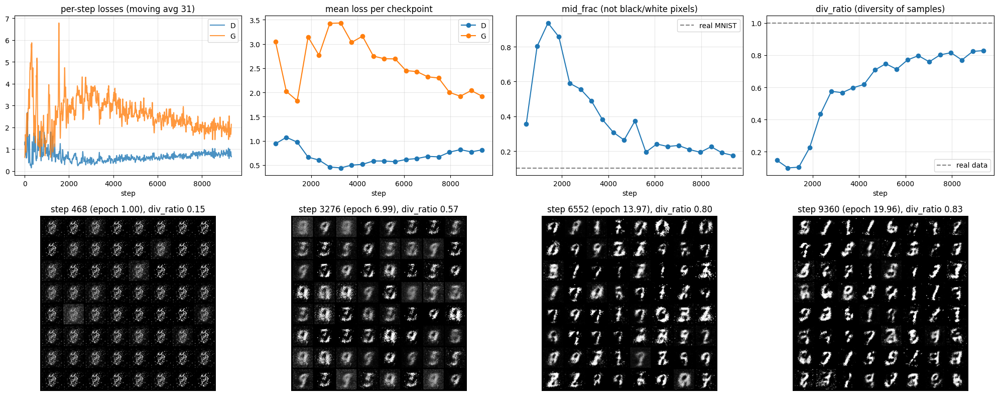

 step     epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g   lr_d
 6084 12.972281 0.615424 2.449720  0.240733   0.770260 0.0002 0.0002
 6552 13.970149 0.634041 2.430637  0.226443   0.796855 0.0002 0.0002
 7020 14.968017 0.679388 2.321873  0.232402   0.758573 0.0002 0.0002
 7488 15.965885 0.669333 2.297093  0.209119   0.801894 0.0002 0.0002
 7956 16.963753 0.766319 2.000045  0.193165   0.815149 0.0002 0.0002
 8424 17.961620 0.818312 1.921087  0.225157   0.769999 0.0002 0.0002
 8892 18.959488 0.771708 2.038825  0.190061   0.823386 0.0002 0.0002
 9360 19.957356 0.814299 1.920685  0.175049   0.828442 0.0002 0.0002


In [4]:
RUNS['Baseline'] = dict(title='Baseline: default settings, all digits',
                      args=dict(lr_g=2e-4, lr_d=2e-4, batch_size=128, n_epoch=20, eval_every=468))
run('Baseline')
show_run('Baseline')

## 2. Change one param at a time
Each run changes a single thing from the baseline.

**Strong discriminator** (lr_d 1e-3, 5× the generator), all digits.         
No collapse: the samples stay varied (diversity 0.83), though after 20 epochs the output still leans toward 1s.

/usr/bin/python3 -u gan.py --out_dir results/Discriminator --lr_g 0.0002 --lr_d 0.001 --batch_size 128 --n_epoch 20 --eval_every 468
samples per digit: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
[step 468 | epoch 1.00/20]: loss_d: 0.937, loss_g: 4.885, mid_frac: 0.535 (real 0.103), div_ratio: 0.112, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 936 | epoch 2.00/20]: loss_d: 0.947, loss_g: 4.120, mid_frac: 0.974 (real 0.103), div_ratio: 0.100, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1404 | epoch 2.99/20]: loss_d: 0.652, loss_g: 3.395, mid_frac: 0.968 (real 0.103), div_ratio: 0.166, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1872 | epoch 3.99/20]: loss_d: 0.386, loss_g: 5.398, mid_frac: 0.841 (real 0.103), div_ratio: 0.276, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2340 | epoch 4.99/20]: loss_d: 0.342, loss_g: 4.721, mid_frac: 0.661 (real 0.103), div_ratio: 0.357, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2808 | epoch 5.99/20]: loss_d: 0.367, loss_g: 3.961, mid_frac: 0.729 (real 0.103), div_ratio: 0.393, lr

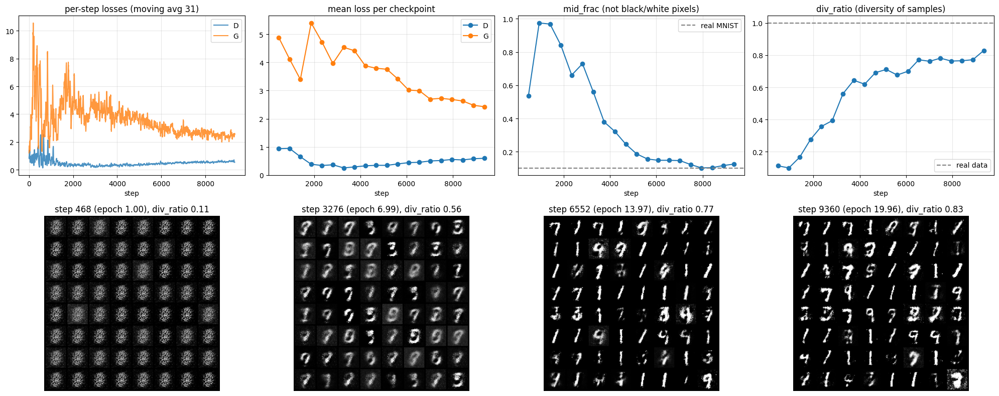

 step     epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g  lr_d
 6084 12.972281 0.443289 3.017681  0.149006   0.699907 0.0002 0.001
 6552 13.970149 0.455494 2.994111  0.148936   0.771684 0.0002 0.001
 7020 14.968017 0.502890 2.695387  0.147162   0.761706 0.0002 0.001
 7488 15.965885 0.519078 2.725562  0.123176   0.781326 0.0002 0.001
 7956 16.963753 0.555041 2.683547  0.103217   0.763470 0.0002 0.001
 8424 17.961620 0.538850 2.630903  0.104866   0.765358 0.0002 0.001
 8892 18.959488 0.581695 2.477500  0.117457   0.771798 0.0002 0.001
 9360 19.957356 0.597139 2.426798  0.126171   0.828673 0.0002 0.001


In [5]:
RUNS['Discriminator'] = dict(title='Strong discriminator',
                      args=dict(lr_g=2e-4, lr_d=1e-3, batch_size=128, n_epoch=20, eval_every=468))
run('Discriminator')
show_run('Discriminator')

**Batch size 1**, all digits, equal lr.         
No collapse: the losses settle around D ≈ 1.2, G ≈ 1.0 and diversity reaches 1.0 with all digits present.

/usr/bin/python3 -u gan.py --out_dir results/All digits BS1 equal lr --lr_g 0.0002 --lr_d 0.0002 --batch_size 1 --n_epoch 1 --max_steps 30000 --eval_every 3000
samples per digit: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
[step 3000 | epoch 0.05/1]: loss_d: 1.316, loss_g: 1.065, mid_frac: 0.815 (real 0.103), div_ratio: 0.165, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 6000 | epoch 0.10/1]: loss_d: 1.205, loss_g: 1.228, mid_frac: 0.347 (real 0.103), div_ratio: 0.226, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 9000 | epoch 0.15/1]: loss_d: 1.152, loss_g: 1.230, mid_frac: 0.392 (real 0.103), div_ratio: 0.634, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 12000 | epoch 0.20/1]: loss_d: 1.316, loss_g: 0.828, mid_frac: 0.333 (real 0.103), div_ratio: 0.797, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 15000 | epoch 0.25/1]: loss_d: 1.326, loss_g: 0.823, mid_frac: 0.210 (real 0.103), div_ratio: 0.861, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 18000 | epoch 0.30/1]: loss_d: 1.334, loss_g: 0.818, mid_frac: 0.183 (real 0.

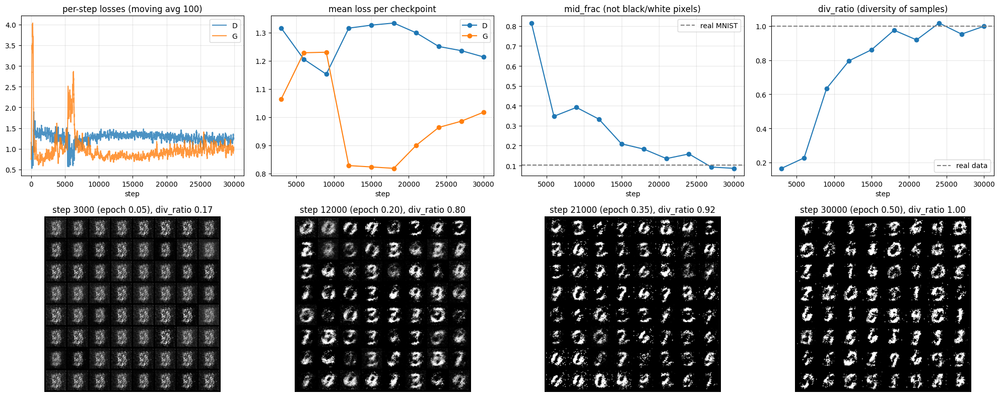

 step  epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g   lr_d
 9000   0.15 1.152202 1.230289  0.391896   0.634006 0.0002 0.0002
12000   0.20 1.315724 0.827806  0.333117   0.796591 0.0002 0.0002
15000   0.25 1.326339 0.823044  0.209577   0.861309 0.0002 0.0002
18000   0.30 1.333842 0.818060  0.182513   0.975915 0.0002 0.0002
21000   0.35 1.298960 0.899968  0.135154   0.919034 0.0002 0.0002
24000   0.40 1.250576 0.963283  0.158407   1.017999 0.0002 0.0002
27000   0.45 1.235810 0.985327  0.092559   0.953078 0.0002 0.0002
30000   0.50 1.213271 1.017595  0.086261   0.999447 0.0002 0.0002


In [6]:
RUNS['All digits BS1 equal lr'] = dict(title='All digits, BS1, equal lr, 30k steps',
                      args=dict(lr_g=0.0002, lr_d=0.0002, batch_size=1, n_epoch=1, max_steps=30000, eval_every=3000))
run('All digits BS1 equal lr')
show_run('All digits BS1 equal lr')

**Narrow dataset**: only digits 1 and 7, default settings.      
No collapse: the generator produces both digits at roughly their training share.

/usr/bin/python3 -u gan.py --out_dir results/Classes equal lr --lr_g 0.0002 --lr_d 0.0002 --batch_size 128 --n_epoch 40 --eval_every 468 --classes 1 7
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 468 | epoch 4.59/40]: loss_d: 0.572, loss_g: 5.112, mid_frac: 0.011 (real 0.077), div_ratio: 0.024, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 936 | epoch 9.18/40]: loss_d: 0.129, loss_g: 8.563, mid_frac: 0.023 (real 0.077), div_ratio: 0.131, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 1404 | epoch 13.76/40]: loss_d: 0.119, loss_g: 27.033, mid_frac: 0.534 (real 0.077), div_ratio: 0.660, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 1872 | epoch 18.35/40]: loss_d: 0.201, loss_g: 11.501, mid_frac: 0.236 (real 0.077), div_ratio: 0.516, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 2340 | epoch 22.94/40]: loss_d: 0.317, loss_g: 7.512, mid_frac: 0.424 (real 0.077), div_ratio: 0.258, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 2808 | epoch 27.53/40]: loss_d: 0.373, loss_g: 4.523, mid_frac: 0.324 (real 0.077), div_ratio: 0.414, lr

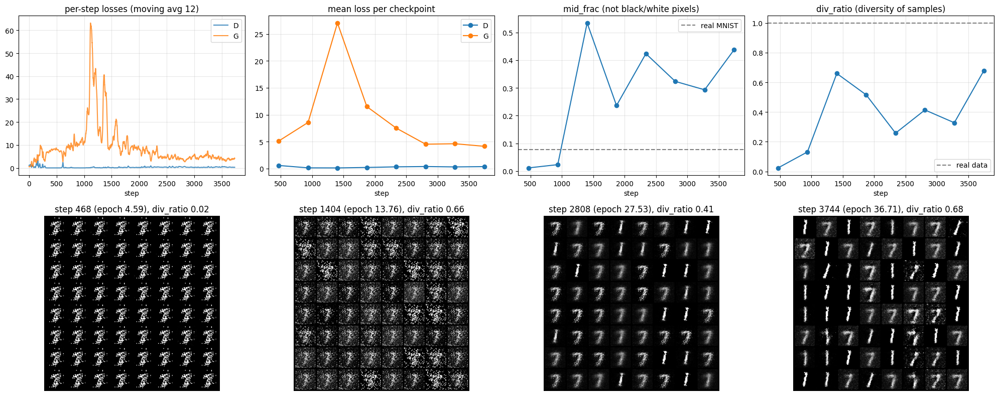

 step     epoch   loss_d    loss_g  mid_frac  div_ratio   lr_g   lr_d
  468  4.588235 0.572354  5.112085  0.011485   0.023814 0.0002 0.0002
  936  9.176471 0.129273  8.563361  0.023293   0.131367 0.0002 0.0002
 1404 13.764706 0.118566 27.033315  0.534364   0.659906 0.0002 0.0002
 1872 18.352941 0.201455 11.501002  0.236453   0.515871 0.0002 0.0002
 2340 22.941176 0.316769  7.511613  0.423649   0.258147 0.0002 0.0002
 2808 27.529412 0.372667  4.523466  0.323576   0.414102 0.0002 0.0002
 3276 32.117647 0.303022  4.606682  0.293263   0.328124 0.0002 0.0002
 3744 36.705882 0.358858  4.130209  0.437410   0.676676 0.0002 0.0002


In [7]:
RUNS['Classes equal lr'] = dict(title='Chosen classes, equal lr',
                      args=dict(lr_g=0.0002, lr_d=0.0002, batch_size=128, n_epoch=40, eval_every=468, classes=[1, 7]))
run('Classes equal lr')
show_run('Classes equal lr')

**Moderate imbalance**: all ten digits, 1 and 7 kept in full, the other eight cut to 10%, so 1 and 7 are already 74% of the data.               
Over 200 epochs the generated digit shares follow the training shares, so "mostly 1s and 7s" reflects the data, not collapse.

/usr/bin/python3 -u gan.py --out_dir results/Imbalance r=0.1 --lr_g 0.0002 --lr_d 0.0002 --batch_size 128 --n_epoch 200 --eval_every 1380 --class_fractions 0:0.1,2:0.1,3:0.1,4:0.1,5:0.1,6:0.1,8:0.1,9:0.1
samples per digit: [621, 6742, 575, 601, 570, 537, 574, 6265, 594, 573]
[step 1380 | epoch 10.00/200]: loss_d: 0.631, loss_g: 4.477, mid_frac: 0.888 (real 0.086), div_ratio: 0.104, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 2760 | epoch 20.00/200]: loss_d: 0.650, loss_g: 2.969, mid_frac: 0.627 (real 0.086), div_ratio: 0.544, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 4140 | epoch 30.00/200]: loss_d: 0.541, loss_g: 2.842, mid_frac: 0.170 (real 0.086), div_ratio: 0.676, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 5520 | epoch 40.00/200]: loss_d: 0.672, loss_g: 2.251, mid_frac: 0.184 (real 0.086), div_ratio: 0.713, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 6900 | epoch 50.00/200]: loss_d: 0.767, loss_g: 1.881, mid_frac: 0.123 (real 0.086), div_ratio: 0.755, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 8280 | epoch 60.00/200]: los

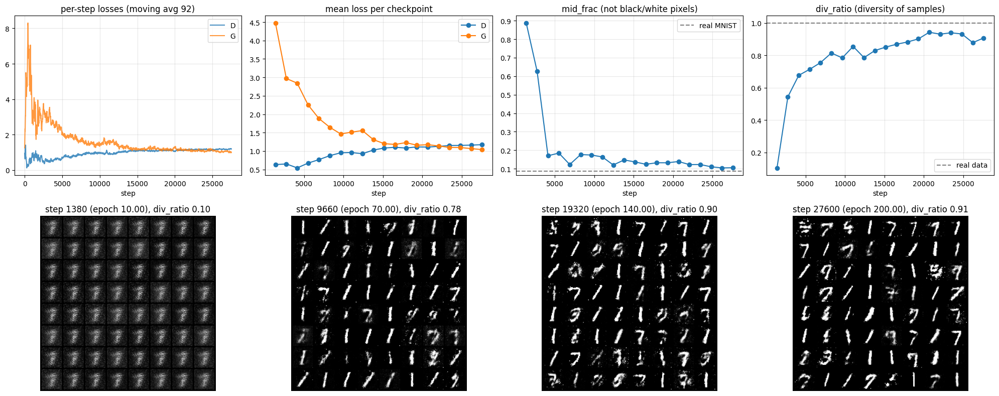

 step  epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g   lr_d
17940  130.0 1.080864 1.228414  0.132175   0.882601 0.0002 0.0002
19320  140.0 1.111383 1.156767  0.131946   0.901596 0.0002 0.0002
20700  150.0 1.107640 1.172676  0.138941   0.942634 0.0002 0.0002
22080  160.0 1.125768 1.136810  0.122120   0.930723 0.0002 0.0002
23460  170.0 1.150259 1.097631  0.122588   0.939382 0.0002 0.0002
24840  180.0 1.152303 1.095279  0.110362   0.931901 0.0002 0.0002
26220  190.0 1.160677 1.065071  0.104278   0.878258 0.0002 0.0002
27600  200.0 1.172623 1.038486  0.105374   0.907332 0.0002 0.0002


In [8]:
def skew(r):
    return ','.join(f'{d}:{r}' for d in (0, 2, 3, 4, 5, 6, 8, 9))

RUNS['Imbalance r=0.1'] = dict(title='Minority digits at 10%, equal lr, 200 epochs',
    args=dict(lr_g=2e-4, lr_d=2e-4, batch_size=128, n_epoch=200, eval_every=1380, class_fractions=skew(0.1)))
run('Imbalance r=0.1')
show_run('Imbalance r=0.1')

**Extreme imbalance**: minority digits cut to 0.5%, so 1 and 7 are 98% of the data.             
Over 200 epochs the output again follows the training share, so imbalance alone does not collapse the generator.

/usr/bin/python3 -u gan.py --out_dir results/Imbalance r=0.005 --lr_g 0.0002 --lr_d 0.0002 --batch_size 128 --n_epoch 200 --eval_every 1030 --class_fractions 0:0.005,2:0.005,3:0.005,4:0.005,5:0.005,6:0.005,8:0.005,9:0.005
samples per digit: [30, 6742, 31, 29, 40, 23, 29, 6265, 27, 25]
[step 1030 | epoch 9.90/200]: loss_d: 0.470, loss_g: 6.917, mid_frac: 0.199 (real 0.077), div_ratio: 0.384, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 2060 | epoch 19.81/200]: loss_d: 0.233, loss_g: 9.455, mid_frac: 0.120 (real 0.077), div_ratio: 0.115, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 3090 | epoch 29.71/200]: loss_d: 0.273, loss_g: 5.256, mid_frac: 0.729 (real 0.077), div_ratio: 0.437, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 4120 | epoch 39.62/200]: loss_d: 0.330, loss_g: 4.165, mid_frac: 0.215 (real 0.077), div_ratio: 0.649, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 5150 | epoch 49.52/200]: loss_d: 0.425, loss_g: 3.307, mid_frac: 0.163 (real 0.077), div_ratio: 0.654, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 6180 | epoch 59.42/

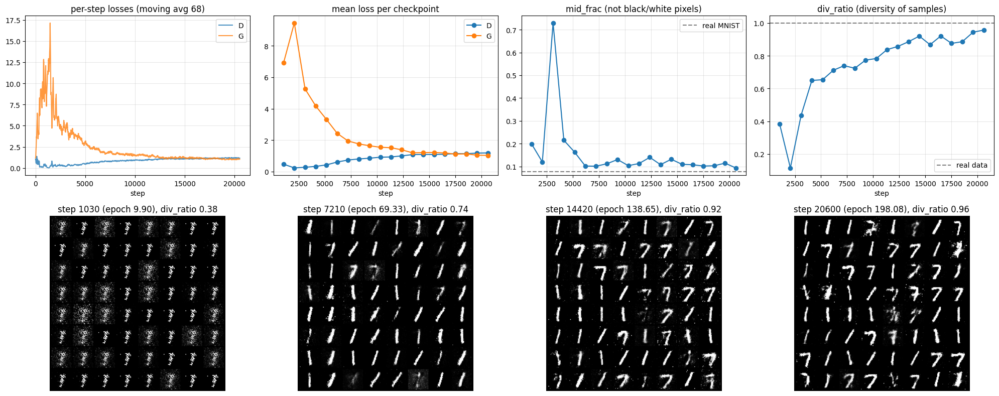

 step      epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g   lr_d
13390 128.750000 1.081286 1.194800  0.107776   0.885672 0.0002 0.0002
14420 138.653846 1.091073 1.206523  0.131602   0.919999 0.0002 0.0002
15450 148.557692 1.086455 1.214501  0.109201   0.867405 0.0002 0.0002
16480 158.461538 1.104589 1.185154  0.107392   0.920648 0.0002 0.0002
17510 168.365385 1.142821 1.110839  0.101767   0.875542 0.0002 0.0002
18540 178.269231 1.135865 1.125424  0.103042   0.885783 0.0002 0.0002
19570 188.173077 1.175947 1.042925  0.114502   0.943474 0.0002 0.0002
20600 198.076923 1.186684 1.029600  0.093571   0.956765 0.0002 0.0002


In [9]:
RUNS['Imbalance r=0.005'] = dict(title='Minority digits at 0.5%, equal lr, 200 epochs',
    args=dict(lr_g=2e-4, lr_d=2e-4, batch_size=128, n_epoch=200, eval_every=1030, class_fractions=skew(0.005)))
run('Imbalance r=0.005')
show_run('Imbalance r=0.005')

## 3. Narrow dataset + learning-rate imbalance

**Digits 1 and 7 + strong discriminator** (lr_d 5×).        
Frozen collapse: from about epoch 14, D loss is 0 and G loss is pinned at 100, diversity is constant at 0.056, and every noise vector gives the same binarized image.

/usr/bin/python3 -u gan.py --out_dir results/Classes + discriminator --lr_g 0.0002 --lr_d 0.001 --batch_size 128 --n_epoch 40 --eval_every 468 --classes 1 7
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 468 | epoch 4.59/40]: loss_d: 0.711, loss_g: 7.086, mid_frac: 0.009 (real 0.077), div_ratio: 0.021, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 936 | epoch 9.18/40]: loss_d: 0.015, loss_g: 30.164, mid_frac: 0.084 (real 0.077), div_ratio: 0.056, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1404 | epoch 13.76/40]: loss_d: 0.000, loss_g: 100.000, mid_frac: 0.084 (real 0.077), div_ratio: 0.056, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1872 | epoch 18.35/40]: loss_d: 0.000, loss_g: 100.000, mid_frac: 0.084 (real 0.077), div_ratio: 0.056, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2340 | epoch 22.94/40]: loss_d: 0.000, loss_g: 100.000, mid_frac: 0.084 (real 0.077), div_ratio: 0.056, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2808 | epoch 27.53/40]: loss_d: 0.000, loss_g: 99.999, mid_frac: 0.084 (real 0.077), div_rati

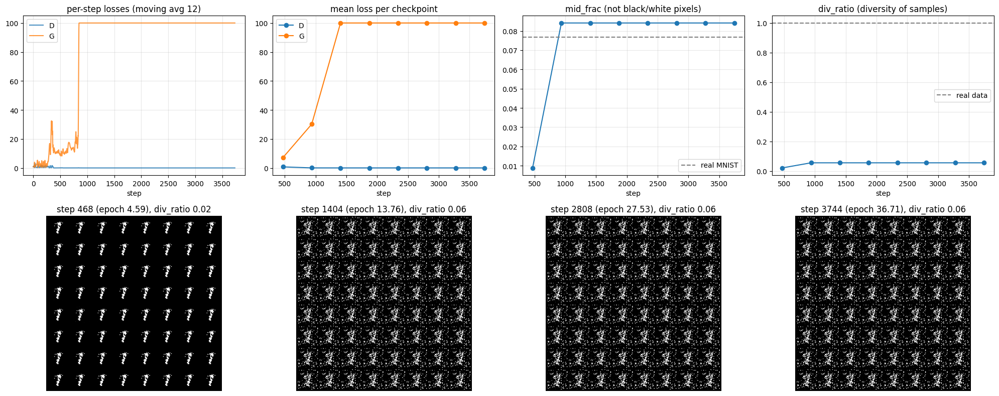

 step     epoch   loss_d     loss_g  mid_frac  div_ratio   lr_g  lr_d
  468  4.588235 0.710550   7.085999  0.008879   0.021416 0.0002 0.001
  936  9.176471 0.015052  30.163675  0.084114   0.055831 0.0002 0.001
 1404 13.764706 0.000124 100.000000  0.084109   0.055827 0.0002 0.001
 1872 18.352941 0.000052 100.000000  0.084109   0.055827 0.0002 0.001
 2340 22.941176 0.000029  99.999623  0.084109   0.055827 0.0002 0.001
 2808 27.529412 0.000018  99.998796  0.084109   0.055827 0.0002 0.001
 3276 32.117647 0.000012 100.000000  0.084109   0.055827 0.0002 0.001
 3744 36.705882 0.000008  99.998863  0.084109   0.055827 0.0002 0.001


In [10]:
RUNS['Classes + discriminator'] = dict(title='Chosen classes + Strong discriminator',
                      args=dict(lr_g=2e-4, lr_d=1e-3, batch_size=128, n_epoch=40, eval_every=468, classes=[1, 7]))
run('Classes + discriminator')
show_run('Classes + discriminator')

**Same setup, seed 1**, to check reproducibility.       
This seed does not freeze: it drifts toward 1s, but keeps varied samples, so the collapse depends on the seed.

/usr/bin/python3 -u gan.py --out_dir results/Classes + discriminator seed 1 --lr_g 0.0002 --lr_d 0.001 --batch_size 128 --n_epoch 40 --eval_every 468 --classes 1 7 --seed 1
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 468 | epoch 4.59/40]: loss_d: 0.737, loss_g: 5.056, mid_frac: 1.000 (real 0.077), div_ratio: 0.168, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 936 | epoch 9.18/40]: loss_d: 0.660, loss_g: 7.628, mid_frac: 0.448 (real 0.077), div_ratio: 0.251, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1404 | epoch 13.76/40]: loss_d: 0.464, loss_g: 5.553, mid_frac: 0.676 (real 0.077), div_ratio: 0.403, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1872 | epoch 18.35/40]: loss_d: 0.303, loss_g: 4.238, mid_frac: 0.728 (real 0.077), div_ratio: 0.618, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2340 | epoch 22.94/40]: loss_d: 0.304, loss_g: 4.427, mid_frac: 0.191 (real 0.077), div_ratio: 0.502, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2808 | epoch 27.53/40]: loss_d: 0.311, loss_g: 4.085, mid_frac: 0.331 (real 0.077), 

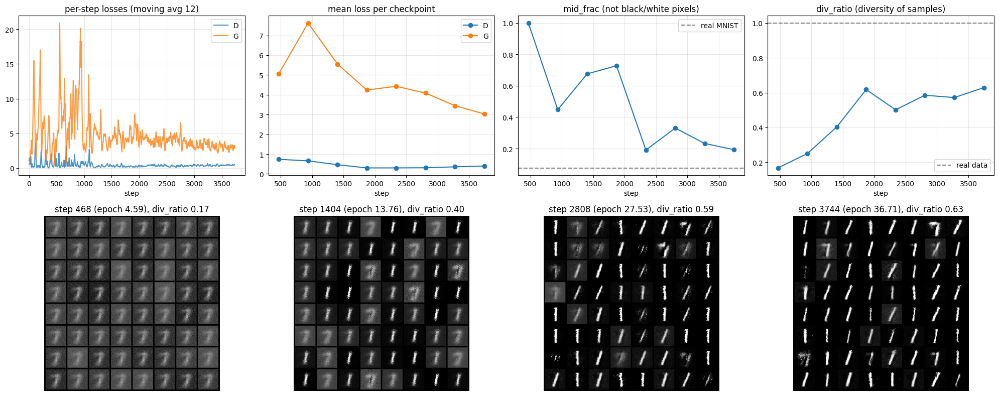

 step     epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g  lr_d
  468  4.588235 0.737260 5.055729  0.999955   0.167921 0.0002 0.001
  936  9.176471 0.660358 7.627835  0.447819   0.250652 0.0002 0.001
 1404 13.764706 0.464094 5.552680  0.675597   0.403424 0.0002 0.001
 1872 18.352941 0.303041 4.237635  0.727778   0.617624 0.0002 0.001
 2340 22.941176 0.303625 4.427060  0.190589   0.501593 0.0002 0.001
 2808 27.529412 0.310723 4.084773  0.330716   0.585012 0.0002 0.001
 3276 32.117647 0.358398 3.446510  0.232606   0.571898 0.0002 0.001
 3744 36.705882 0.401257 3.027973  0.192896   0.628653 0.0002 0.001


In [11]:
RUNS['Classes + discriminator seed 1'] = dict(title='Chosen classes + Strong discriminator, seed 1',
                      args=dict(lr_g=0.0002, lr_d=0.001, batch_size=128, n_epoch=40, eval_every=468, classes=[1, 7], seed=1))
run('Classes + discriminator seed 1')
show_run('Classes + discriminator seed 1')

**Digits 1 and 7 + strong generator** (lr_g 5×), the imbalance reversed.        
Also a frozen collapse: D loss 0, G loss creeping from 15 to 21, and near-zero diversity with one identical noise image.

/usr/bin/python3 -u gan.py --out_dir results/Classes + generator --lr_g 0.001 --lr_d 0.0002 --batch_size 128 --n_epoch 40 --eval_every 468 --classes 1 7
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 468 | epoch 4.59/40]: loss_d: 0.196, loss_g: 9.684, mid_frac: 0.000 (real 0.077), div_ratio: 0.062, lr_g: 1.0e-03, lr_d: 2.0e-04
[step 936 | epoch 9.18/40]: loss_d: 0.007, loss_g: 13.106, mid_frac: 0.000 (real 0.077), div_ratio: 0.022, lr_g: 1.0e-03, lr_d: 2.0e-04
[step 1404 | epoch 13.76/40]: loss_d: 0.000, loss_g: 15.721, mid_frac: 0.000 (real 0.077), div_ratio: 0.045, lr_g: 1.0e-03, lr_d: 2.0e-04
[step 1872 | epoch 18.35/40]: loss_d: 0.000, loss_g: 17.477, mid_frac: 0.000 (real 0.077), div_ratio: 0.056, lr_g: 1.0e-03, lr_d: 2.0e-04
[step 2340 | epoch 22.94/40]: loss_d: 0.000, loss_g: 18.686, mid_frac: 0.000 (real 0.077), div_ratio: 0.016, lr_g: 1.0e-03, lr_d: 2.0e-04
[step 2808 | epoch 27.53/40]: loss_d: 0.000, loss_g: 19.414, mid_frac: 0.000 (real 0.077), div_ratio: 0.00

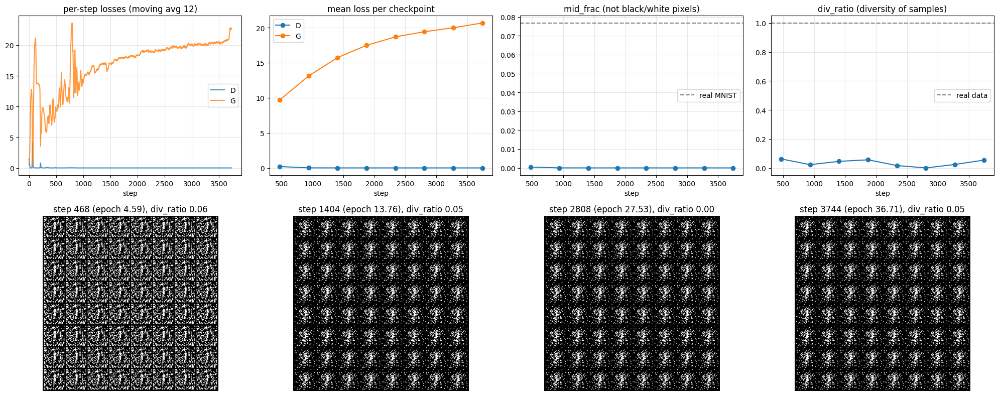

 step     epoch   loss_d    loss_g  mid_frac  div_ratio  lr_g   lr_d
  468  4.588235 0.195982  9.683647  0.000438   0.061929 0.001 0.0002
  936  9.176471 0.006975 13.106238  0.000010   0.022480 0.001 0.0002
 1404 13.764706 0.000168 15.720637  0.000000   0.045294 0.001 0.0002
 1872 18.352941 0.000029 17.476777  0.000000   0.055924 0.001 0.0002
 2340 22.941176 0.000014 18.685856  0.000000   0.016263 0.001 0.0002
 2808 27.529412 0.000008 19.414365  0.000000   0.000000 0.001 0.0002
 3276 32.117647 0.000006 19.979875  0.000005   0.023827 0.001 0.0002
 3744 36.705882 0.000005 20.661081  0.000000   0.053679 0.001 0.0002


In [12]:
RUNS['Classes + generator'] = dict(title='Chosen classes + Strong generator',
                      args=dict(lr_g=1e-3, lr_d=2e-4, batch_size=128, n_epoch=40, eval_every=468, classes=[1, 7]))
run('Classes + generator')
show_run('Classes + generator')

**Skewed dataset + strong discriminator**: all ten digits, the eight minority digits cut to 5%, lr_d 5×.            
Partial mode collapse (mode dropping) rather than complete collapse: the 7s almost disappear (94% 1s vs 44% in the data) while the 1s stay varied.

/usr/bin/python3 -u gan.py --out_dir results/Skewed classes + discriminator --lr_g 0.0002 --lr_d 0.001 --batch_size 128 --n_epoch 40 --eval_every 468 --class_fractions 0:0.05,2:0.05,3:0.05,4:0.05,5:0.05,6:0.05,8:0.05,9:0.05
samples per digit: [307, 6742, 297, 276, 297, 252, 285, 6265, 285, 275]
[step 468 | epoch 3.90/40]: loss_d: 0.922, loss_g: 4.364, mid_frac: 0.171 (real 0.081), div_ratio: 0.073, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 936 | epoch 7.80/40]: loss_d: 0.422, loss_g: 9.750, mid_frac: 0.413 (real 0.081), div_ratio: 0.238, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1404 | epoch 11.70/40]: loss_d: 0.531, loss_g: 6.134, mid_frac: 0.745 (real 0.081), div_ratio: 0.172, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 1872 | epoch 15.60/40]: loss_d: 0.354, loss_g: 4.505, mid_frac: 0.748 (real 0.081), div_ratio: 0.385, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2340 | epoch 19.50/40]: loss_d: 0.274, loss_g: 5.492, mid_frac: 0.531 (real 0.081), div_ratio: 0.574, lr_g: 2.0e-04, lr_d: 1.0e-03
[step 2808 | epoch 23.4

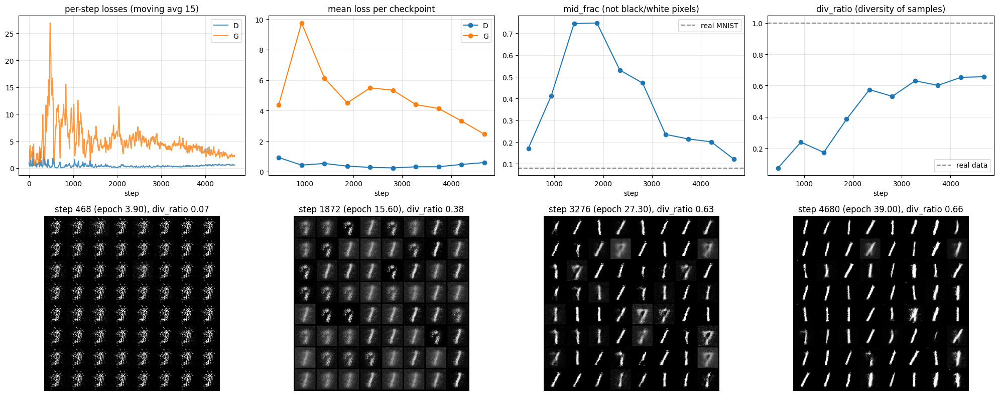

 step  epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g  lr_d
 1404   11.7 0.530842 6.133934  0.744888   0.172206 0.0002 0.001
 1872   15.6 0.354348 4.504963  0.747638   0.384993 0.0002 0.001
 2340   19.5 0.273731 5.491868  0.531205   0.573809 0.0002 0.001
 2808   23.4 0.238605 5.336587  0.471391   0.530697 0.0002 0.001
 3276   27.3 0.311642 4.395242  0.235451   0.630130 0.0002 0.001
 3744   31.2 0.315558 4.136936  0.214316   0.600906 0.0002 0.001
 4212   35.1 0.467419 3.318520  0.201152   0.652259 0.0002 0.001
 4680   39.0 0.590957 2.452375  0.120875   0.656173 0.0002 0.001


In [13]:
RUNS['Skewed classes + discriminator'] = dict(title='Skewed classes + Strong discriminator',
                      args=dict(lr_g=0.0002, lr_d=0.001, batch_size=128, n_epoch=40, eval_every=468, class_fractions='0:0.05,2:0.05,3:0.05,4:0.05,5:0.05,6:0.05,8:0.05,9:0.05'))
run('Skewed classes + discriminator')
show_run('Skewed classes + discriminator')

## 4. Narrow dataset + batch size 1

**Digits 1 and 7, batch size 1, equal lr, 13 epochs; from step 126,000 a linear schedule over 20,000 steps lowers lr_g 10× (to 2e-5), lr_d stays at 2e-4.** Before the schedule the 1s vanish around step 12,000 and the output keeps collapsing onto one 7 while G loss swings between 5 and 28. Once the generator is slowed down it can no longer chase the discriminator: D loss stays flat near 0.05, G loss stays high (11–19), diversity is constant at about 0.67 for the last 30,000 steps, and every noise vector (fixed, fresh or interpolated) gives the same binarized 7, so the 1s never come back.

/usr/bin/python3 -u gan.py --out_dir results/Classes BS1 equal lr --lr_g 0.0002 --lr_d 0.0002 --batch_size 1 --n_epoch 13 --eval_every 6000 --classes 1 7 --sched_start 126000 --sched_steps 20000 --sched_lr_g 2e-05 --sched_lr_d 0.0002
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 6000 | epoch 0.46/13]: loss_d: 1.238, loss_g: 1.070, mid_frac: 0.165 (real 0.077), div_ratio: 0.495, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 12000 | epoch 0.92/13]: loss_d: 0.551, loss_g: 4.424, mid_frac: 0.002 (real 0.077), div_ratio: 0.190, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 18000 | epoch 1.38/13]: loss_d: 0.117, loss_g: 7.625, mid_frac: 0.001 (real 0.077), div_ratio: 0.123, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 24000 | epoch 1.85/13]: loss_d: 0.125, loss_g: 8.215, mid_frac: 0.002 (real 0.077), div_ratio: 0.310, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 30000 | epoch 2.31/13]: loss_d: 0.016, loss_g: 25.963, mid_frac: 0.000 (real 0.077), div_ratio: 0.002, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 36000 | epoch 2.77/

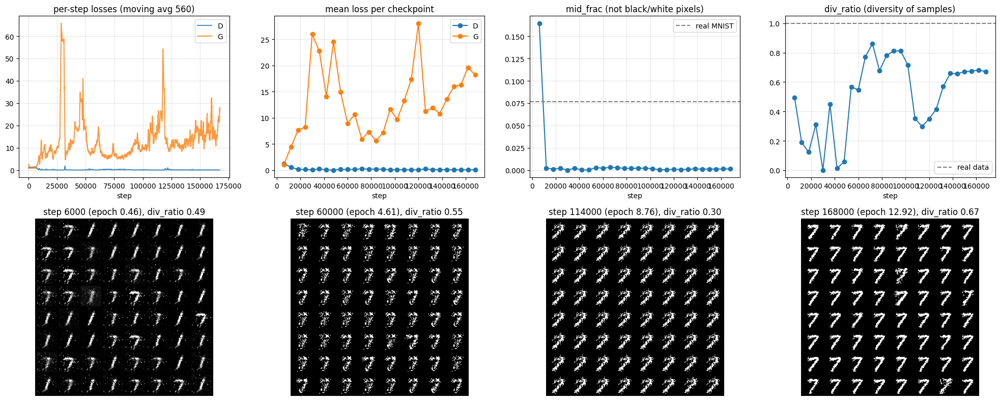

  step     epoch   loss_d    loss_g  mid_frac  div_ratio     lr_g   lr_d
126000  9.687092 0.228897 11.192046  0.000583   0.415119 0.000200 0.0002
132000 10.148382 0.075970 11.912996  0.000942   0.570156 0.000146 0.0002
138000 10.609672 0.069106 10.774085  0.001211   0.659384 0.000092 0.0002
144000 11.070962 0.075595 13.531880  0.001116   0.656081 0.000038 0.0002
150000 11.532252 0.038620 15.951257  0.001066   0.671902 0.000020 0.0002
156000 11.993542 0.045912 16.315971  0.001161   0.672790 0.000020 0.0002
162000 12.454832 0.040489 19.594140  0.001271   0.682332 0.000020 0.0002
168000 12.916122 0.045240 18.203849  0.001251   0.670534 0.000020 0.0002


In [14]:
RUNS['Classes BS1 equal lr'] = dict(title='Chosen classes, BS1, equal lr, lr schedule from step 126k',
                      args=dict(lr_g=2e-4, lr_d=2e-4, batch_size=1, n_epoch=13, eval_every=6000, classes=[1, 7],
                                sched_start=126000, sched_steps=20000, sched_lr_g=2e-5, sched_lr_d=2e-4))
run('Classes BS1 equal lr')
show_run('Classes BS1 equal lr')

**Same setup, seed 1, 3 epochs.**           
Frozen collapse: from step 18,000 D loss is 0, G loss is flat at about 94, diversity is constant at 0.229, and every sample is the same binarized image.

/usr/bin/python3 -u gan.py --out_dir results/Classes BS1 equal lr seed 1 --lr_g 0.0002 --lr_d 0.0002 --batch_size 1 --n_epoch 3 --seed 1 --eval_every 3000 --classes 1 7
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 3000 | epoch 0.23/3]: loss_d: 1.201, loss_g: 1.229, mid_frac: 0.021 (real 0.077), div_ratio: 0.074, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 6000 | epoch 0.46/3]: loss_d: 0.073, loss_g: 9.414, mid_frac: 0.000 (real 0.077), div_ratio: 0.000, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 9000 | epoch 0.69/3]: loss_d: 0.062, loss_g: 12.579, mid_frac: 0.000 (real 0.077), div_ratio: 0.062, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 12000 | epoch 0.92/3]: loss_d: 0.030, loss_g: 17.435, mid_frac: 0.000 (real 0.077), div_ratio: 0.020, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 15000 | epoch 1.15/3]: loss_d: 0.019, loss_g: 18.578, mid_frac: 0.000 (real 0.077), div_ratio: 0.000, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 18000 | epoch 1.38/3]: loss_d: 0.000, loss_g: 48.023, mid_frac: 0.017 (real 0.077), div_r

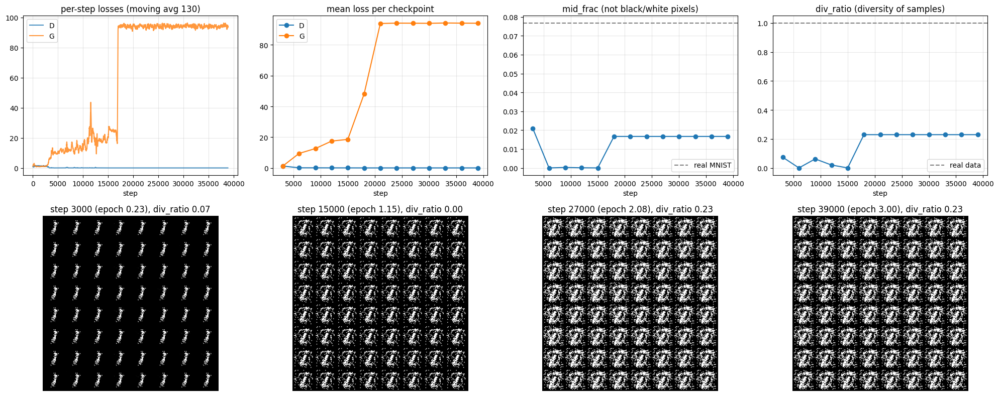

 step    epoch       loss_d    loss_g  mid_frac  div_ratio   lr_g   lr_d
18000 1.383870 2.485607e-04 48.023317  0.016676   0.229467 0.0002 0.0002
21000 1.614515 4.141978e-24 93.916697  0.016676   0.229467 0.0002 0.0002
24000 1.845160 1.748323e-30 94.178161  0.016676   0.229467 0.0002 0.0002
27000 2.075805 1.413788e-27 94.117009  0.016676   0.229467 0.0002 0.0002
30000 2.306450 1.073865e-29 94.039989  0.016676   0.229467 0.0002 0.0002
33000 2.537095 7.493575e-29 94.266102  0.016676   0.229467 0.0002 0.0002
36000 2.767740 2.004463e-30 94.160712  0.016676   0.229467 0.0002 0.0002
39000 2.998385 1.998059e-30 94.099922  0.016676   0.229467 0.0002 0.0002


In [15]:
RUNS['Classes BS1 equal lr seed 1'] = dict(title='Chosen classes, BS1, equal lr, seed 1',
                      args=dict(lr_g=2e-4, lr_d=2e-4, batch_size=1, n_epoch=3, seed=1, eval_every=3000, classes=[1, 7]))
run('Classes BS1 equal lr seed 1')
show_run('Classes BS1 equal lr seed 1')

**Same setup, seed 2, 3 epochs.**           
No collapse: diversity stays near 1.0 with only a mild lean toward 1s, so with batch size 1 two of three seeds collapse.

/usr/bin/python3 -u gan.py --out_dir results/Classes BS1 equal lr seed 2 --lr_g 0.0002 --lr_d 0.0002 --batch_size 1 --n_epoch 3 --seed 2 --eval_every 3000 --classes 1 7
samples per digit: [0, 6742, 0, 0, 0, 0, 0, 6265, 0, 0]
[step 3000 | epoch 0.23/3]: loss_d: 1.151, loss_g: 1.389, mid_frac: 0.211 (real 0.077), div_ratio: 0.131, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 6000 | epoch 0.46/3]: loss_d: 1.245, loss_g: 0.914, mid_frac: 0.218 (real 0.077), div_ratio: 0.598, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 9000 | epoch 0.69/3]: loss_d: 1.278, loss_g: 0.923, mid_frac: 0.146 (real 0.077), div_ratio: 0.736, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 12000 | epoch 0.92/3]: loss_d: 1.206, loss_g: 1.002, mid_frac: 0.063 (real 0.077), div_ratio: 0.769, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 15000 | epoch 1.15/3]: loss_d: 1.163, loss_g: 1.141, mid_frac: 0.041 (real 0.077), div_ratio: 0.893, lr_g: 2.0e-04, lr_d: 2.0e-04
[step 18000 | epoch 1.38/3]: loss_d: 1.198, loss_g: 1.037, mid_frac: 0.038 (real 0.077), div_ratio

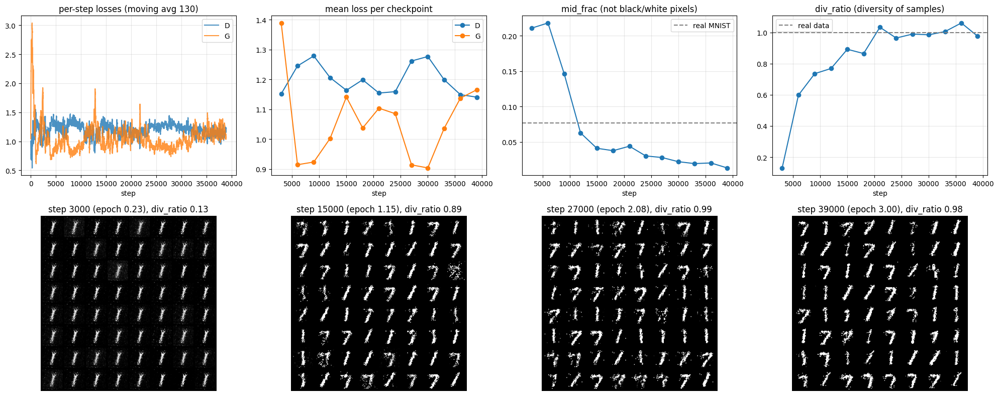

 step    epoch   loss_d   loss_g  mid_frac  div_ratio   lr_g   lr_d
18000 1.383870 1.198471 1.037021  0.037692   0.865264 0.0002 0.0002
21000 1.614515 1.154075 1.103303  0.044025   1.034089 0.0002 0.0002
24000 1.845160 1.158679 1.084936  0.030293   0.964785 0.0002 0.0002
27000 2.075805 1.261343 0.913486  0.028046   0.990165 0.0002 0.0002
30000 2.306450 1.276369 0.903346  0.022187   0.985372 0.0002 0.0002
33000 2.537095 1.198768 1.035487  0.019452   1.006462 0.0002 0.0002
36000 2.767740 1.148669 1.136880  0.020398   1.061487 0.0002 0.0002
39000 2.998385 1.140350 1.164858  0.013383   0.976517 0.0002 0.0002


In [16]:
RUNS['Classes BS1 equal lr seed 2'] = dict(title='Chosen classes, BS1, equal lr, seed 2',
                      args=dict(lr_g=2e-4, lr_d=2e-4, batch_size=1, n_epoch=3, seed=2, eval_every=3000, classes=[1, 7]))
run('Classes BS1 equal lr seed 2')
show_run('Classes BS1 equal lr seed 2')

## Same image check
Loads the final generator of a run and feeds it new noise (other seed) plus a line between two noise vectors. A collapsed generator gives the same image everywhere.

In [17]:
sys.path.insert(0, '.')
import gan

def fresh_noise_check(name, seed=777):
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    G = gan.Generator(64, 784).to(dev)
    G.load_state_dict(torch.load(Path('results') / name / 'G.pth', map_location=dev)); G.eval()
    g = torch.Generator().manual_seed(seed)
    z_fixed = torch.randn(256, 64, generator=torch.Generator().manual_seed(1234)).to(dev)
    z_fresh = torch.randn(256, 64, generator=g).to(dev)
    z0, z1 = torch.randn(1, 64, generator=g).to(dev), torch.randn(1, 64, generator=g).to(dev)
    z_line = z0 + torch.linspace(0, 1, 16, device=dev)[:, None] * (z1 - z0)
    with torch.no_grad():
        im_fixed, im_fresh, im_line = G(z_fixed), G(z_fresh), G(z_line)
    d_fixed, d_fresh = torch.pdist(im_fixed).mean().item(), torch.pdist(im_fresh).mean().item()
    print(f'{name}: mean pairwise distance fixed noise {d_fixed:.3f} | fresh noise {d_fresh:.3f} (ratio {d_fresh / d_fixed:.2f})')
    fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw=dict(width_ratios=[1, 2]))
    ax[0].imshow(make_grid(im_fresh[:64].view(-1, 1, 28, 28).cpu(), nrow=8, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); ax[0].set_title('fresh noise, 64 samples')
    ax[1].imshow(make_grid(im_line.view(-1, 1, 28, 28).cpu(), nrow=16, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); ax[1].set_title('interpolation between two noise vectors')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

Classes + discriminator: mean pairwise distance fixed noise 0.947 | fresh noise 0.945 (ratio 1.00)


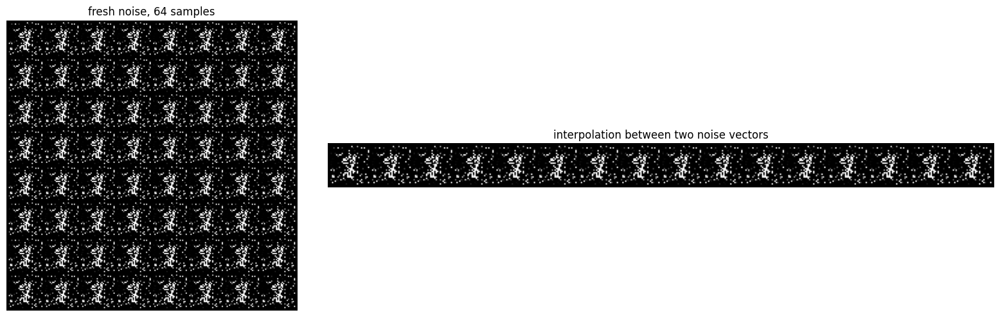

Classes BS1 equal lr: mean pairwise distance fixed noise 11.376 | fresh noise 11.019 (ratio 0.97)


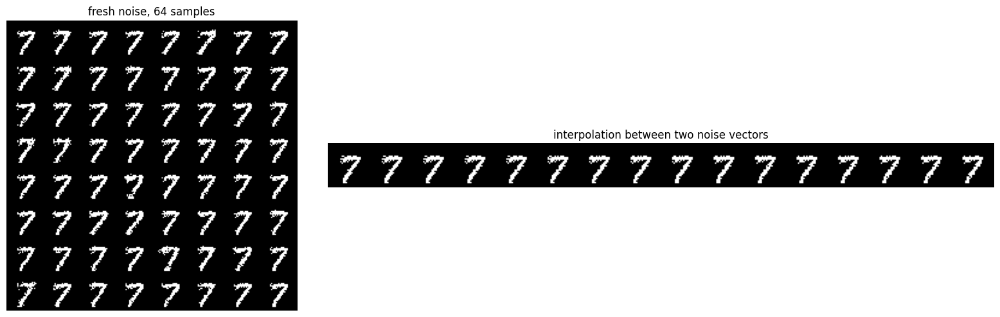

Classes BS1 equal lr seed 1: mean pairwise distance fixed noise 3.893 | fresh noise 4.006 (ratio 1.03)


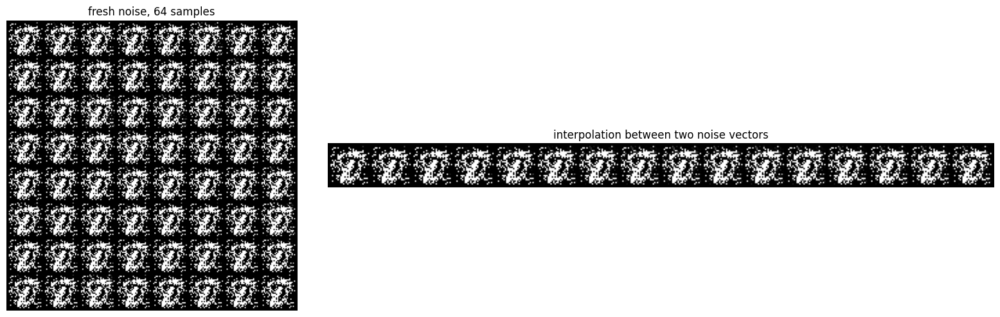

In [18]:
fresh_noise_check('Classes + discriminator')
fresh_noise_check('Classes BS1 equal lr')
fresh_noise_check('Classes BS1 equal lr seed 1')

## Mode histogram
`div_ratio` says the samples are alike, but not *which* digits are produced. Here a small MNIST classifier (trained for 2 epochs) labels 1000 generated images from fresh noise, and we count how many land on each digit. A healthy generator spreads over the digits it was trained on, a collapsed one piles up in one bar.

Caveat: a collapsed generator often outputs a speckled pattern that is not a real digit, so the classifier assigns it a digit arbitrarily. `conf` is the mean classifier confidence: low values mean the images do not look like digits to the classifier.

Red dots are the share of each digit in the run's own training data. A healthy generator follows them; a collapsed one puts clearly more than its share on a few digits.

In [19]:
import math
import torch.nn as nn
from torchvision import datasets, transforms

CLF = None

def get_classifier(epochs=2):
    global CLF
    if CLF is not None:
        return CLF
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,)), transforms.Lambda(lambda x: x.view(-1))])
    train = datasets.MNIST('./mnist_data/', train=True, transform=tf, download=True)
    test = datasets.MNIST('./mnist_data/', train=False, transform=tf, download=True)
    loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)
    clf = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)).to(dev)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    for _ in range(epochs):
        for x, y in loader:
            opt.zero_grad(); nn.functional.cross_entropy(clf(x.to(dev)), y.to(dev)).backward(); opt.step()
    with torch.no_grad():
        xs = torch.stack([test[i][0] for i in range(len(test))]).to(dev)
        acc = (clf(xs).argmax(1).cpu() == test.targets).float().mean().item()
    print(f'classifier test accuracy: {acc:.3f}')
    CLF = clf.eval()
    return CLF


def mode_histogram(names, n=1000, seed=777):
    clf = get_classifier()
    dev = next(clf.parameters()).device
    cols = min(3, len(names)); rows = math.ceil(len(names) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5.5 * cols, 3.6 * rows), squeeze=False)
    for ax, name in zip(axes.flat, names):
        G = gan.Generator(64, 784).to(dev)
        G.load_state_dict(torch.load(Path('results') / name / 'G.pth', map_location=dev)); G.eval()
        z = torch.randn(n, 64, generator=torch.Generator().manual_seed(seed)).to(dev)
        with torch.no_grad():
            probs = torch.softmax(clf(G(z)), 1)
        counts = torch.bincount(probs.argmax(1).cpu(), minlength=10)
        ax.bar(range(10), counts.numpy(), label='generated'); ax.set_xticks(range(10))
        hist_file = Path('results') / name / 'history.json'
        if hist_file.exists():   # share of each digit in this run's training data, scaled to n samples
            cc = np.array(json.load(open(hist_file))['class_counts'], dtype=float)
            ax.scatter(range(10), cc / cc.sum() * n, c='red', zorder=5, label='training share')
        ax.set_title(f'{name}\ntop digit {counts.max().item() / n:.0%} | conf {probs.max(1).values.mean().item():.2f}', fontsize=10)
        ax.set_xlabel('digit predicted by classifier'); ax.set_ylabel(f'count of {n}'); ax.grid(alpha=.3); ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(names):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

classifier test accuracy: 0.955


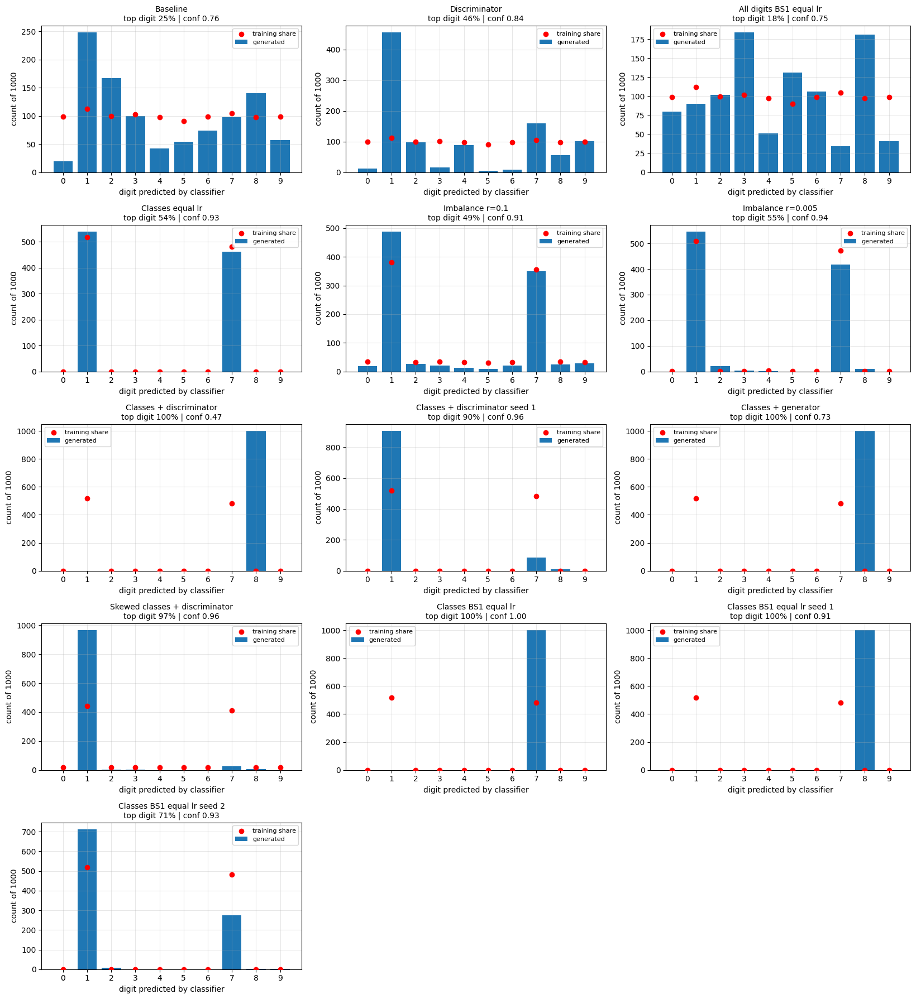

In [20]:
# every run that has finished and saved a generator
mode_histogram([n for n in RUNS if (Path('results') / n / 'G.pth').exists()])

## Summary of all runs

In [21]:
rows = []
for name, cfg in RUNS.items():
    if not (Path('results') / name / 'history.json').exists():
        continue
    h, log = load(name)
    a = cfg['args']
    rows.append(dict(run=name, lr_g=a.get('lr_g', 2e-4), lr_d=a.get('lr_d', 2e-4), batch=a.get('batch_size', 128),
                     digits=a.get('classes', 'all'), seed=a.get('seed', 42), steps=int(log['step'].iloc[-1]),
                     final_loss_d=round(log['loss_d'].iloc[-1], 3), final_loss_g=round(log['loss_g'].iloc[-1], 3),
                     final_mid_frac=round(log['mid_frac'].iloc[-1], 3), final_div_ratio=round(log['div_ratio'].iloc[-1], 3)))
pd.DataFrame(rows)

,run,lr_g,lr_d,batch,digits,seed,steps,final_loss_d,final_loss_g,final_mid_frac,final_div_ratio
0,Baseline,0.0002,0.0002,128,all,42,9360,0.814,1.921,0.175,0.828
1,Discriminator,0.0002,0.0010,128,all,42,9360,0.597,2.427,0.126,0.829
2,All digits BS1 equal lr,0.0002,0.0002,1,all,42,30000,1.213,1.018,0.086,0.999
3,Classes equal lr,0.0002,0.0002,128,"[1, 7]",42,3744,0.359,4.130,0.437,0.677
4,Imbalance r=0.1,0.0002,0.0002,128,all,42,27600,1.173,1.038,0.105,0.907
5,Imbalance r=0.005,0.0002,0.0002,128,all,42,20600,1.187,1.030,0.094,0.957
6,Classes + discriminator,0.0002,0.0010,128,"[1, 7]",42,3744,0.000,99.999,0.084,0.056
7,Classes + discriminator seed 1,0.0002,0.0010,128,"[1, 7]",1,3744,0.401,3.028,0.193,0.629
8,Classes + generator,0.0010,0.0002,128,"[1, 7]",42,3744,0.000,20.661,0.000,0.054
9,Skewed classes + discriminator,0.0002,0.0010,128,all,42,4680,0.591,2.452,0.121,0.656
